# Lab work # 1

> Student name    - Rodion Ostapenko

> Group           - CS-32

In [3]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 20
rng = np.random.default_rng(SEED)

Функція перетворює текстове подання символів у біполярні вектори ознак ($X$) та формує діагональну матрицю цільових значень ($T$).


In [4]:
def patterns_to_arrays(patterns):
    """Перетворити словник символів на біполярні вектори X і цілі T."""
    letters = list(patterns)
    rows_per_letter = [tuple(patterns[k]) for k in letters]
    heights = {len(rows) for rows in rows_per_letter}
    widths = {len(row) for rows in rows_per_letter for row in rows}
    h, w = heights.pop(), widths.pop()
    binary = np.array([[int(c) for row in rows for c in row] for rows in rows_per_letter], dtype=int)
    X = 2 * binary - 1
    T = -np.ones((4, 4), dtype=int)
    np.fill_diagonal(T, 1)
    return letters, X, T, (h, w)

Функція візуалізує вхідні символи у вигляді чорно-білих зображень разом із їхніми цільовими векторами.

In [5]:
def plot_glyphs(X, labels, shape, targets=None, title='Вхідні символи'):
    n = len(X)
    fig, axs = plt.subplots(1, n, figsize=(3.0 * n, 3.4))
    axs = np.atleast_1d(axs)
    for i, (ax, x, label) in enumerate(zip(axs, X, labels)):
        ax.imshow(np.asarray(x).reshape(shape), cmap='gray_r', vmin=-1, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        subtitle = f'\nЦіль: {np.asarray(targets[i]).tolist()}' if targets is not None else ''
        ax.set_title(str(label) + subtitle, fontsize=10)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()

Функція додає фіктивну ознаку $x_0=1$ (bias) до кожного вхідного вектора для зміщення гіперплощини прийняття рішень.

In [6]:
def augment_bias(X):
    X = np.asarray(X, dtype=int)
    return np.c_[np.ones(len(X), dtype=int), X]

Функція реалізує класичне однопрохідне навчання за правилом Хебба, обчислюючи матрицю ваг як суму зовнішніх добутків вхідних і цільових векторів.


In [7]:
def fit_hebb_one_pass(X, T, eta=1):
    Xa = augment_bias(X)
    T = np.asarray(T, dtype=int)
    weights = np.zeros((Xa.shape[1], T.shape[1]), dtype=int)
    for xa, t in zip(Xa, T):
        weights += eta * np.outer(xa, t)
    return weights

Блок містить біполярну функцію активації, функцію прямого проходження сигналу через мережу та метрику для оцінки точності повного збігу векторів.

In [9]:
def bipolar_step(scores):
    """Активація методички: +1 при S > 0, інакше -1."""
    return np.where(np.asarray(scores) > 0, 1, -1).astype(int)

assert bipolar_step([-3, 0, 2]).tolist() == [-1, -1, 1]

def forward(X, W):
    """Повернути матриці сум S і біполярних прогнозів Y."""
    S = augment_bias(X) @ np.asarray(W)
    return S, bipolar_step(S)


def exact_accuracy(pred, targets):
    """Частка прикладів, для яких правильний ВЕСЬ вихідний вектор."""
    pred, targets = np.asarray(pred), np.asarray(targets)
    return float(np.mean(np.all(pred == targets, axis=1)))

Функція перевіряє набір даних на наявність суперечливих міток (однакові вхідні вектори з різними цілями), що унеможливлює навчання.

In [10]:
def contradictory_pairs(X, T):
    """Знайти пари індексів із однаковими входами і різними цілями."""
    bad = []
    for i in range(len(X)):
        for j in range(i + 1, len(X)):
            if np.array_equal(X[i], X[j]) and not np.array_equal(T[i], T[j]):
                bad.append((i, j))
    return bad

Функція виводить детальну таблицю порівняння бажаних цілей та реальних прогнозів мережі для кожного вхідного символу.

In [11]:
def inspect_predictions(X, T, W, labels):
    S, Y = forward(X, W)
    header = 'Вхід | бажаний T             | прогноз Y             | S                       | результат'
    print(header)
    print('-' * len(header))
    for name, t, y, score in zip(labels, T, Y, S):
        status = '✓ правильно' if np.array_equal(t, y) else '✗ помилка'
        print(f'{name:^5} | {str(t.tolist()):<21} | {str(y.tolist()):<21} | {str(score.tolist()):<23} | {status}')
    return exact_accuracy(Y, T)

Функція виконує ітеративне навчання мережі (дельта-правило) з обмеженням кількості епох та захистом від зациклювання і суперечливих даних.

In [12]:
def train_hebb(X, T, max_epochs=100, eta=1):
    """Ітеративне кероване навчання Хебба; повертає W, історію та статус.

    Статуси: converged, cycle, max_epochs, contradictory_targets.
    """
    X, T = np.asarray(X, dtype=int), np.asarray(T, dtype=int)
    Xa = augment_bias(X)
    W = np.zeros((Xa.shape[1], T.shape[1]), dtype=int)
    history = []
    if contradictory_pairs(X, T):
        return W, history, 'contradictory_targets'

    seen = {W.tobytes()}
    for epoch in range(1, max_epochs + 1):
        updates = 0
        for xa, t in zip(Xa, T):
            y = bipolar_step(xa @ W)
            if not np.array_equal(y, t):
                W += eta * np.outer(xa, t)
                updates += 1

        _, predicted = forward(X, W)
        accuracy = exact_accuracy(predicted, T)
        history.append({'epoch': epoch, 'updates': updates, 'accuracy': accuracy,
                        'weight_norm': float(np.linalg.norm(W))})
        if accuracy == 1.0:
            return W, history, 'converged'
        key = W.tobytes()
        if key in seen:
            return W, history, 'cycle'
        seen.add(key)
    return W, history, 'max_epochs'

In [14]:
def plot_history(history, title='Хід навчання'):
    epochs = [h['epoch'] for h in history]
    accuracies = [h['accuracy'] for h in history]
    updates = [h['updates'] for h in history]
    fig, ax = plt.subplots(figsize=(7.5, 3.5))
    ax.plot(epochs, accuracies, 'o-', label='Точність повного вектора')
    ax.set_xlabel('Епоха')
    ax.set_ylabel('Частка правильних прикладів')
    ax.set_ylim(-0.05, 1.05)
    ax2 = ax.twinx()
    ax2.plot(epochs, updates, 's--', color='tab:orange', label='Оновлення ваг')
    ax2.set_ylabel('Кількість оновлень')
    ax.legend(loc='upper left')
    ax2.legend(loc='lower right')
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

In [15]:
def plot_weight_maps(W, labels, shape):
    fig, axs = plt.subplots(1, len(labels), figsize=(3.1 * len(labels), 3.1))
    scale = max(1, np.abs(W[1:]).max())
    for j, (ax, label) in enumerate(zip(np.atleast_1d(axs), labels)):
        im = ax.imshow(W[1:, j].reshape(shape), cmap='coolwarm', vmin=-scale, vmax=scale)
        ax.set_title(f'Нейрон «{label}», bias={W[0,j]}')
        ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=np.atleast_1d(axs).tolist(), shrink=0.65, label='Вага')
    plt.show()

### Індивідуальна робота

Літери: ['О', 'С', 'Т', 'П']
Рецепторних нейронів: n=20; вихідних нейронів: m=4; параметрів: (n+1)·m=84
Вектори цілей:
 [[ 1 -1 -1 -1]
 [-1  1 -1 -1]
 [-1 -1  1 -1]
 [-1 -1 -1  1]]


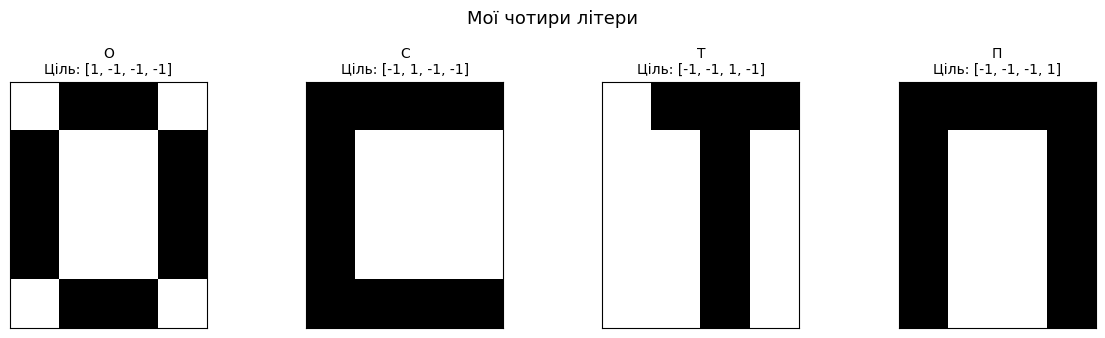

In [16]:
STUDENT_PATTERNS = {
    'О': ('0110', '1001', '1001', '1001', '0110'),
    'С': ('1111', '1000', '1000', '1000', '1111'),
    'Т': ('0111', '0010', '0010', '0010', '0010'),
    'П': ('1111', '1001', '1001', '1001', '1001')
}

my_letters, X_my, T_my, my_shape = patterns_to_arrays(STUDENT_PATTERNS)
my_n = X_my.shape[1]
my_m = T_my.shape[1]
print('Літери:', my_letters)
print(f'Рецепторних нейронів: n={my_n}; вихідних нейронів: m={my_m}; параметрів: (n+1)·m={(my_n+1)*my_m}')
print('Вектори цілей:\n', T_my)
plot_glyphs(X_my, my_letters, my_shape, T_my, title='Мої чотири літери')

Однопрохідне навчання:
Вхід | бажаний T             | прогноз Y             | S                       | результат
------------------------------------------------------------------------------------------
  О   | [1, -1, -1, -1]       | [1, -1, -1, -1]       | [6, -22, -38, -18]      | ✓ правильно
  С   | [-1, 1, -1, -1]       | [-1, 1, -1, -1]       | [-26, 2, -38, -18]      | ✓ правильно
  Т   | [-1, -1, 1, -1]       | [-1, -1, 1, -1]       | [-18, -14, 26, -26]     | ✓ правильно
  П   | [-1, -1, -1, 1]       | [-1, -1, -1, 1]       | [-18, -14, -46, 6]      | ✓ правильно
Ітеративне навчання: converged
Вхід | бажаний T             | прогноз Y             | S                       | результат
------------------------------------------------------------------------------------------
  О   | [1, -1, -1, -1]       | [1, -1, -1, -1]       | [6, -22, -38, -18]      | ✓ правильно
  С   | [-1, 1, -1, -1]       | [-1, 1, -1, -1]       | [-26, 2, -38, -18]      | ✓ правильно
  Т   | [-1, -1, 1

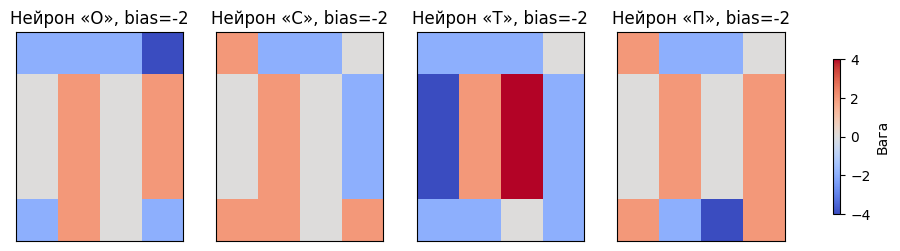

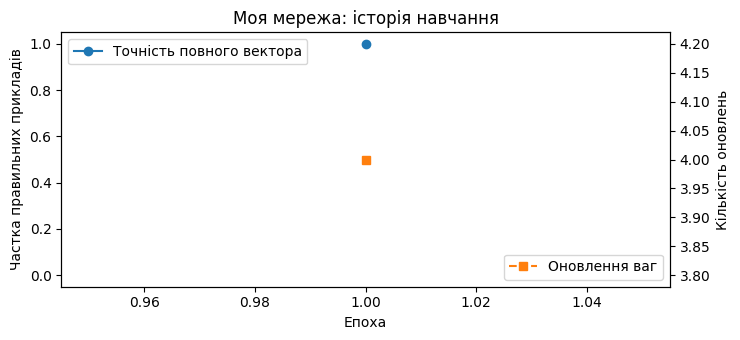

In [17]:
W_my_once = fit_hebb_one_pass(X_my, T_my)
W_my, my_history, my_status = train_hebb(X_my, T_my, max_epochs=100)

print('Однопрохідне навчання:')
acc_my_one = inspect_predictions(X_my, T_my, W_my_once, my_letters)
print('Ітеративне навчання:', my_status)
acc_my = inspect_predictions(X_my, T_my, W_my, my_letters)
print(f'Порівняння: один прохід {acc_my_one:.0%}; ітеративно {acc_my:.0%}; епох {len(my_history)}')
plot_weight_maps(W_my, my_letters, my_shape)
plot_history(my_history, 'Моя мережа: історія навчання')

### Використано одношарову нейронну мережу прямого поширення з 20 рецепторними нейронами (плюс один нейрон зміщення) та 4 вихідними нейронами, що відповідає розмірності задачі (зображення 5х4 пікселів, 4 класи). Біполярне представлення ознак (-1 та 1) замість бінарного (0 та 1) є критично важливим для алгоритму Хебба, оскільки нульові значення входів не викликали б оновлення ваг, а біполярні цілі забезпечують симетричне гальмування та збудження синапсів.

### **Нерозв'язний набiр даних**

Літери: ['О', 'С', 'Р', 'П']
Рецепторних нейронів: n=20; вихідних нейронів: m=4; параметрів: (n+1)·m=84
Вектори цілей:
 [[ 1 -1 -1 -1]
 [-1  1 -1 -1]
 [-1 -1  1 -1]
 [-1 -1 -1  1]]


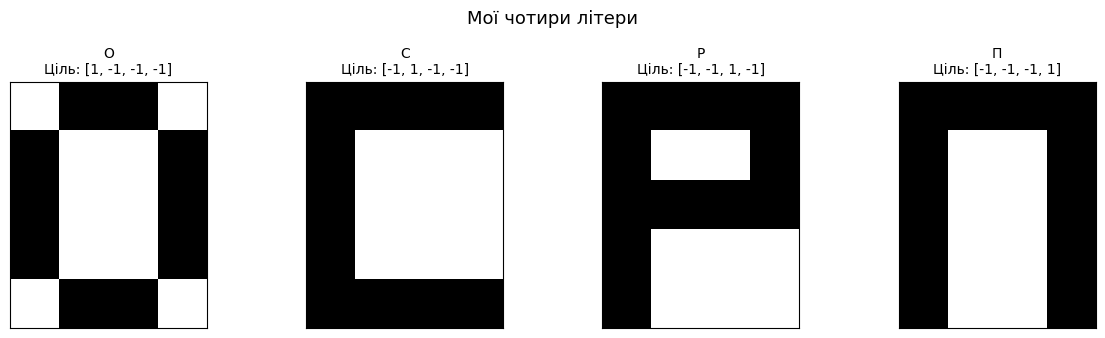

In [29]:
STUDENT_PATTERNS = {
    'О': ('0110', '1001', '1001', '1001', '0110'),
    'С': ('1111', '1000', '1000', '1000', '1111'),
    'Р': ('1111', '1001', '1111', '1000', '1000'),
    'П': ('1111', '1001', '1001', '1001', '1001')
}

my_letters, X_my, T_my, my_shape = patterns_to_arrays(STUDENT_PATTERNS)
my_n = X_my.shape[1]
my_m = T_my.shape[1]
print('Літери:', my_letters)
print(f'Рецепторних нейронів: n={my_n}; вихідних нейронів: m={my_m}; параметрів: (n+1)·m={(my_n+1)*my_m}')
print('Вектори цілей:\n', T_my)
plot_glyphs(X_my, my_letters, my_shape, T_my, title='Мої чотири літери')

Однопрохідне навчання:
Вхід | бажаний T             | прогноз Y             | S                       | результат
------------------------------------------------------------------------------------------
  О   | [1, -1, -1, -1]       | [-1, -1, -1, -1]      | [0, -28, -32, -24]      | ✗ помилка
  С   | [-1, 1, -1, -1]       | [-1, -1, -1, -1]      | [-32, -4, -32, -24]     | ✗ помилка
  Р   | [-1, -1, 1, -1]       | [-1, -1, -1, -1]      | [-36, -32, -4, -20]     | ✗ помилка
  П   | [-1, -1, -1, 1]       | [-1, -1, -1, -1]      | [-36, -32, -28, -12]    | ✗ помилка
Ітеративне навчання: max_epochs
Вхід | бажаний T             | прогноз Y             | S                       | результат
------------------------------------------------------------------------------------------
  О   | [1, -1, -1, -1]       | [-1, -1, -1, -1]      | [0, -2800, -3200, -2400] | ✗ помилка
  С   | [-1, 1, -1, -1]       | [-1, -1, -1, -1]      | [-3200, -400, -3200, -2400] | ✗ помилка
  Р   | [-1, -1, 1, -1] 

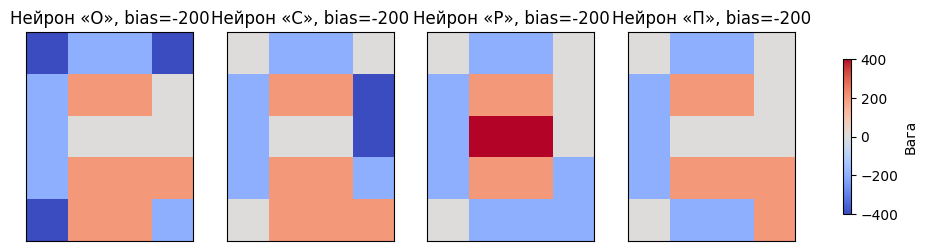

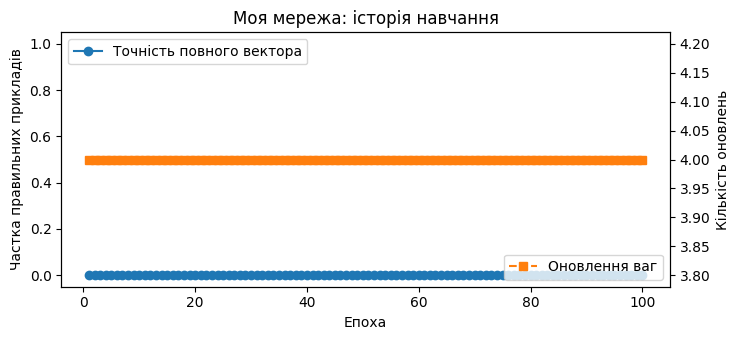

In [30]:
W_my_once = fit_hebb_one_pass(X_my, T_my)
W_my, my_history, my_status = train_hebb(X_my, T_my, max_epochs=100)

print('Однопрохідне навчання:')
acc_my_one = inspect_predictions(X_my, T_my, W_my_once, my_letters)
print('Ітеративне навчання:', my_status)
acc_my = inspect_predictions(X_my, T_my, W_my, my_letters)
print(f'Порівняння: один прохід {acc_my_one:.0%}; ітеративно {acc_my:.0%}; епох {len(my_history)}')
plot_weight_maps(W_my, my_letters, my_shape)
plot_history(my_history, 'Моя мережа: історія навчання')

### **Чи навчилась мережа:** Так, для першого набору літер («О», «С», «Т», «П») мережа успішно навчилася розпізнавати всі класи зі 100% точністю вже за один прохід. Проте для другого набору («О», «С», «Р», «П») мережа не змогла зійтися навіть за 100 епох ітеративного навчання, показавши 0% точності повного вектора. Через значне перекриття активних пікселів у цих символах не існує такої гіперплощини, яка могла б безпомилково розділити ці чотири класи у 20-вимірному просторі за допомогою простого лінійного класифікатора.

### **Переваги та обмеження алгоритму Хебба:** Головною перевагою є простота реалізації та можливість миттєвого навчання (один прохід) для ортогональних або близьких до них векторів. Основним обмеженням є нездатність розв'язувати лінійно нероздільні задачі та сильна чутливість до корельованих (схожих) вхідних образів, що призводить до перехресних завад (перенавчання одних образів поверх інших).

In [32]:
def predict_letter(x, W, labels):
    x = np.asarray(x, dtype=int).reshape(1, -1)
    S, Y = forward(x, W)
    active = np.flatnonzero(Y[0] == 1)
    result = labels[int(active[0])] if len(active) == 1 else 'невизначено'
    return result, S[0], Y[0]

In [33]:
def flip_pixels(x, n_flips, rng):
    """Поміняти знак у n_flips різних випадково вибраних пікселів."""
    x = np.asarray(x, dtype=int).copy()
    if not 0 <= n_flips <= len(x):
        raise ValueError('Кількість спотворених пікселів має бути від 0 до n.')
    idx = rng.choice(len(x), size=n_flips, replace=False)
    x[idx] *= -1
    return x

Функція перевіряє стійкість навченої мережі до шуму, випадково інвертуючи задану кількість пікселів у вхідних зображеннях.

In [34]:
def noise_experiment(X, labels, W, flips=(0, 1, 2, 3, 4, 5), trials=100, seed=42):
    """Частка правильних однозначних розпізнавань для випадкових спотворень."""
    random_gen = np.random.default_rng(seed)
    results = {}
    for k in flips:
        ok = 0
        for x, label in zip(X, labels):
            for _ in range(trials):
                altered = flip_pixels(x, k, random_gen)
                pred, _, _ = predict_letter(altered, W, labels)
                ok += int(pred == label)
        results[k] = ok / (len(X) * trials)
    return results

0 змінених пікселів → правильних прогнозів: 100.0%
1 змінених пікселів → правильних прогнозів: 93.5%
2 змінених пікселів → правильних прогнозів: 81.5%
3 змінених пікселів → правильних прогнозів: 70.5%


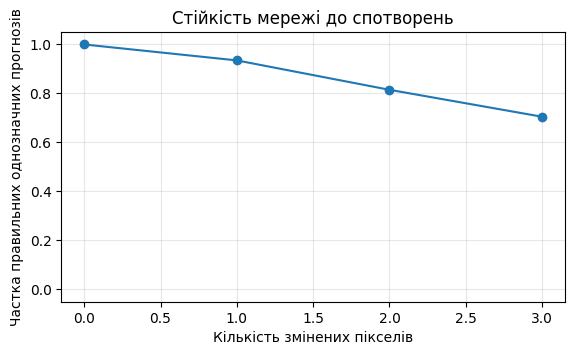

In [40]:
STUDENT_PATTERNS = {
    'О': ('0110', '1001', '1001', '1001', '0110'),
    'С': ('1111', '1000', '1000', '1000', '1111'),
    'Т': ('0111', '0010', '0010', '0010', '0010'),
    'П': ('1111', '1001', '1001', '1001', '1001')
}
my_letters, X_my, T_my, my_shape = patterns_to_arrays(STUDENT_PATTERNS)
W_my_once = fit_hebb_one_pass(X_my, T_my)
W_my, my_history, my_status = train_hebb(X_my, T_my, max_epochs=100)

noise_results = noise_experiment(X_my, my_letters, W_my, flips=(0, 1, 2, 3), trials=50, seed=20)
for k, value in noise_results.items():
    print(f'{k} змінених пікселів → правильних прогнозів: {value:.1%}')
plt.figure(figsize=(6.5, 3.5))
plt.plot(list(noise_results), list(noise_results.values()), 'o-')
plt.ylim(-0.05, 1.05)
plt.xlabel('Кількість змінених пікселів')
plt.ylabel('Частка правильних однозначних прогнозів')
plt.title('Стійкість мережі до спотворень')
plt.grid(alpha=0.3)
plt.show()

### Інверсія одного пікселя знижує точність лише до 93.5%, що підтверджує здатність моделі розпізнавати образ за загальною сукупністю ознак, а не за окремими точками. При збільшенні спотворень до двох та трьох пікселів точність поступово падає до 81.5% та 70.5% відповідно. Мережа не дає різкого збою, оскільки матриця ваг, сформована за алгоритмом Хебба, спирається на скалярний добуток векторів, який залишається достатньо великим для правильної активації навіть при пошкодженні 15% рецепторів.